**Creating and setting up environtmnet for training of faster R-CNN model**

Importing data sets(images) from roboflow and install neccessary package

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install torch torchvision --quiet
!pip install pycocotools --quiet
!pip install roboflow --quiet

from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("annotation-labelling-j8dev").project("vegetables-kqa29")
version = project.version(12)
dataset = version.download("coco")




print("Step 1 complete. Your environment is ready and the dataset has been downloaded.")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 117.5 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Vegetables-12 in coco:: 100%|██████████| 4364/4364 [00:01<00:00, 3559.21it/s]

Step 1 complete. Your environment is ready and the dataset has been downloaded.


Cell 1:


*   Perform basic needed imports
*   Define image transformation also known as data augmentation, used for training by flipping the image horizontally



In [ ]:
import torch
import torchvision
import torchvision.transforms as T
from torchvision.datasets import CocoDetection
from torch.utils.data import DataLoader

import numpy as np
import cv2
from PIL import Image

# Custom transform for morphological erosion
class ErosionTransform:
    def __init__(self, kernel_size=3, iterations=1):
        self.kernel = np.ones((kernel_size, kernel_size), np.uint8)
        self.iterations = iterations

    def __call__(self, img):
        img_np = np.array(img)

        if len(img_np.shape) == 2:
            eroded = cv2.erode(img_np, self.kernel, iterations=self.iterations)
        else:

            eroded = np.zeros_like(img_np)
            for c in range(3):
                eroded[:, :, c] = cv2.erode(img_np[:, :, c], self.kernel, iterations=self.iterations)

        return Image.fromarray(eroded)

def get_transform(train):
    transforms = []
    transforms.append(ErosionTransform(kernel_size=3, iterations=1))
    transforms.append(T.ToTensor())

    if train:
        transforms.append(T.RandomHorizontalFlip(0.5))

    return T.Compose(transforms)

print("Cell 1 executed: Libraries imported and transform function is defined with erosion.")


Cell 1 executed: Libraries imported and transform function is defined with erosion.


Cell 2 perform custom dataset class (with Label Remapping and Empty Annotation Filter):


*   Get the category IDs from the COCO dataset
*   Create a mapping from original ID to a new, sequential ID starting from 1



*   Get the original list of all image IDs
*   Create a new list to store only the IDs of images that have annotations





In [ ]:
#Custom Dataset Class (with Label Remapping AND Empty Annotation Filter)

class VegetableDataset(CocoDetection):
    def __init__(self, root, annFile, transforms):
        super(VegetableDataset, self).__init__(root, annFile)
        self._transforms = transforms

        # --- Fix 1: Label Remapping ---
        self.category_ids = sorted(self.coco.getCatIds())

        self.coco_to_contiguous_id = {
            original_id: new_id + 1
            for new_id, original_id in enumerate(self.category_ids)
        }

        # --- Fix 2: Filter out images with no annotations ---
        ids = list(sorted(self.coco.imgs.keys()))
        print(f"Initially found {len(ids)} images.")

        valid_ids = []
        for i in ids:
            ann_ids = self.coco.getAnnIds(imgIds=i)
            # If the list of annotation IDs is not empty, it's a valid image
            if len(ann_ids) > 0:
                valid_ids.append(i)

        self.ids = valid_ids
        print(f"Removed {len(ids) - len(self.ids)} images with no annotations.")
        print(f"Using {len(self.ids)} images for this dataset.")


    def __getitem__(self, idx):
        img, target = super(VegetableDataset, self).__getitem__(idx)
        image_id = self.ids[idx]

        boxes, labels, areas, iscrowd = [], [], [], []

        for annotation in target:
            original_label = annotation['category_id']
            contiguous_label = self.coco_to_contiguous_id.get(original_label)

            if contiguous_label is not None:
                labels.append(contiguous_label)
                x_min, y_min, width, height = annotation['bbox']
                boxes.append([x_min, y_min, x_min + width, y_min + height])
                areas.append(annotation['area'])
                iscrowd.append(annotation['iscrowd'])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        # IMPORTANT: Handle the case where an image becomes empty after filtering bad labels
        # If there are no valid boxes, return None so our collate_fn can skip it.
        if boxes.shape[0] == 0:
             # This can happen if an image's only annotations were for a class we filtered out.
             # We will handle this in the DataLoader creation.
             return self.__getitem__( (idx + 1) % len(self) )


        labels = torch.as_tensor(labels, dtype=torch.int64)
        areas = torch.as_tensor(areas, dtype=torch.float32)
        iscrowd = torch.as_tensor(iscrowd, dtype=torch.int64)

        formatted_target = {
            "boxes": boxes, "labels": labels, "image_id": torch.tensor([image_id]),
            "area": areas, "iscrowd": iscrowd
        }

        if self._transforms is not None:
            img = self._transforms(img)

        return img, formatted_target

print("FINAL FIX APPLIED: VegetableDataset class now filters empty images and remaps labels.")

FINAL FIX APPLIED: VegetableDataset class now filters empty images and remaps labels.


Cell 3: Create Datasets and DataLoaders

In [ ]:

train_data_dir = '/content/Vegetables-12/train'
train_ann_file = '/content/Vegetables-12/train/_annotations.coco.json'
valid_data_dir = '/content/Vegetables-12/valid'
valid_ann_file = '/content/Vegetables-12/valid/_annotations.coco.json'

# Create the dataset objects
dataset_train = VegetableDataset(root=train_data_dir, annFile=train_ann_file, transforms=get_transform(train=True))
dataset_valid = VegetableDataset(root=valid_data_dir, annFile=valid_ann_file, transforms=get_transform(train=False))

# This custom collate function is needed because images can have different numbers of objects
def collate_fn(batch):
    return tuple(zip(*batch))

batch_size = 4
train_loader = DataLoader(dataset_train, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
valid_loader = DataLoader(dataset_valid, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

print(f"Step 2 complete! Datasets and DataLoaders are ready.")
print(f"Number of training samples: {len(dataset_train)}")
print(f"Number of validation samples: {len(dataset_valid)}")

loading annotations into memory...
Done (t=0.35s)
creating index...
index created!
Initially found 3588 images.
Removed 50 images with no annotations.
Using 3538 images for this dataset.
loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
Initially found 770 images.
Removed 17 images with no annotations.
Using 753 images for this dataset.
Step 2 complete! Datasets and DataLoaders are ready.
Number of training samples: 3538
Number of validation samples: 753


Cell 4: Define the Faster R-CNN Model Function

In [ ]:

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def get_faster_rcnn_model(num_classes):
    # Load a pre-trained Faster R-CNN model from torchvision
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights='DEFAULT')

    # Get the number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features

    # Replace the pre-trained classification head with a new one
    # The number of classes is your custom number of classes + 1 for the background
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)

    return model

print("Cell 4 executed: Model creation function is defined.")

Cell 4 executed: Model creation function is defined.


Cell 5: Instantiate the Model

In [ ]:

num_classes = len(dataset_train.category_ids)

# Create the model
model = get_faster_rcnn_model(num_classes)

# Set the device (can be 'cpu' or 'cuda')
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

print("Step 3 complete! The model is now created correctly.")
print(f"Model will be trained on the correct number of classes: {num_classes}")
print(f"The model is using device: {device}")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:03<00:00, 49.6MB/s]


Step 3 complete! The model is now created correctly.
Model will be trained on the correct number of classes: 39
The model is using device: cuda


MODEL TRAINING WITH UPADTING MODEL'S WEIGHT BY SGD (STOCHASTIC GRADIENT DECENT)

In [ ]:
import matplotlib.pyplot as plt

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

num_epochs = 5

# --- Initialize list to collect losses ---
train_losses = []

print("-----------------------------------------")
print("           STARTING TRAINING           ")
print("-----------------------------------------")

model.to(device)

for epoch in range(num_epochs):
    model.train()

    i = 0
    epoch_loss = 0
    for images, targets in train_loader:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward pass: loss dict
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        loss_value = losses.item()

        # Collect this batch loss
        train_losses.append(loss_value)

        # Optimizer step
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += loss_value

        if (i % 50 == 0):
            print(f"Epoch {epoch+1}/{num_epochs}, Batch {i}/{len(train_loader)}, Loss: {loss_value}")

        i += 1

    print(f"\n---> Epoch {epoch+1} average loss: {epoch_loss / len(train_loader)}\n")

torch.save(model.state_dict(), 'JustinYongWeiLiRCNNtesting_detector.pth')

print("-----------------------------------------")
print("          TRAINING COMPLETE            ")
print("-----------------------------------------")

# --- Plot training loss curve ---
plt.figure(figsize=(8,5))
plt.plot(range(1, len(train_losses)+1), train_losses, 'bo-', alpha=0.6, label='Training Loss (per batch)')
plt.title("Training Loss Curve")
plt.xlabel("Batches (across epochs)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


Saving the trained model into google drive

In [ ]:

!cp /content/JustinYongWeiLiRCNN_detector.pth '/content/drive/MyDrive/'

print("Model successfully copied to the main folder of your Google Drive!")

Cell to automatically discover and create your CLASS_NAMES list

Inspect the categories that were loaded from your annotation file.


The `dataset_valid.coco.cats` is a dictionary where keys are the category IDs and values are dictionaries containing the category name.


Automatically build the CLASS_NAMES list in the correct order.

In [ ]:

print("--- Your Dataset's Categories (ID -> Name) ---")
print(dataset_valid.coco.cats)
print("-" * 50)

# Start with the required background class.
CLASS_NAMES = ["__background__"]

# Get the category IDs and sort them to ensure the order is correct.
category_ids = sorted(dataset_valid.coco.cats.keys())

# Append the category names to the list in the sorted order of their IDs.
for cat_id in category_ids:
    category_name = dataset_valid.coco.cats[cat_id]['name']
    CLASS_NAMES.append(category_name)


# Printing of the generated list
print("\n--- Automatically Generated CLASS_NAMES List ---")
print(CLASS_NAMES)
print("-" * 50)
print("\nYou can now run the other Step 5 cells. The `CLASS_NAMES` variable is ready!")

#Set the num_classes variable for the model loading cell
num_classes = len(CLASS_NAMES) - 1

--- Your Dataset's Categories (ID -> Name) ---
{0: {'id': 0, 'name': 'objects', 'supercategory': 'none'}, 1: {'id': 1, 'name': 'Broccoli', 'supercategory': 'objects'}, 2: {'id': 2, 'name': 'Chilli', 'supercategory': 'objects'}, 3: {'id': 3, 'name': 'DriedChilli', 'supercategory': 'objects'}, 4: {'id': 4, 'name': 'Eggplant', 'supercategory': 'objects'}, 5: {'id': 5, 'name': 'Garlic', 'supercategory': 'objects'}, 6: {'id': 6, 'name': 'Ginger', 'supercategory': 'objects'}, 7: {'id': 7, 'name': 'Grape', 'supercategory': 'objects'}, 8: {'id': 8, 'name': 'Kiwi', 'supercategory': 'objects'}, 9: {'id': 9, 'name': 'Lemon', 'supercategory': 'objects'}, 10: {'id': 10, 'name': 'Lettuce', 'supercategory': 'objects'}, 11: {'id': 11, 'name': 'Pine Apple', 'supercategory': 'objects'}, 12: {'id': 12, 'name': 'Sweet Corn', 'supercategory': 'objects'}, 13: {'id': 13, 'name': 'Sweet Patato', 'supercategory': 'objects'}, 14: {'id': 14, 'name': 'Tomato', 'supercategory': 'objects'}, 15: {'id': 15, 'name': '

Cell to create the Price Lookup Dictionary for the Checkout System

In [ ]:

PRICE_LOOKUP = {
    "objects": 0.00,          # This class cannot be sold

    # --- Vegetables ---
    "Broccoli": 4.50,         # Per piece
    "Chilli": 0.30,           # Per piece (cili padi)
    "DriedChilli": 3.50,      # Per 100g pack
    "Eggplant": 2.20,         # Per piece (terung)
    "Garlic": 0.40,           # Per bulb (bawang putih)
    "Ginger": 1.50,           # Per 100g (halia)
    "Lettuce": 3.80,          # Per head
    "Sweet Corn": 2.50,       # Per cob (jagung manis)
    "Sweet Patato": 1.80,     # Per piece (ubi keledek)
    "Tomato": 0.80,           # Per piece
    "Turnip": 1.90,           # Per piece (sengkuang)
    "bell pepper": 2.80,      # Per piece (lada benggala)
    "cabbage": 4.20,          # Per head (kubis)
    "carrot": 1.10,           # Per piece (lobak merah)
    "cauliflower": 5.50,      # Per head
    "corn": 2.50,             # Assuming same as Sweet Corn
    "cucumber": 1.30,         # Per piece (timun)
    "jalepeno": 0.90,         # Per piece
    "onion": 0.60,            # Per piece (bawang besar)
    "paprika": 1.50,          # Per 100g (serbuk paprika)
    "patato": 1.20,           # Per piece (ubi kentang)
    "peas": 4.00,             # Per 100g pack (kacang pis)
    "raddish": 1.50,          # Per piece (lobak)
    "soy beans": 3.80,        # Per 100g pack (kacang soya)
    "spinach": 3.20,          # Per bunch (bayam)

    # --- Fruits ---
    "Grape": 8.50,            # Per small bunch/pack (anggur)
    "Kiwi": 1.80,             # Per piece
    "Lemon": 1.40,            # Per piece
    "Pine Apple": 5.00,       # Per piece (nanas)
    "apple": 2.00,            # Per piece
    "banana": 0.90,           # Per piece (pisang)
    "beetroot": 2.30,         # Per piece (ubi bit)
    "mango": 6.50,            # Per piece (mangga)
    "orange": 1.80,           # Per piece
    "pear": 2.20,             # Per piece
    "pomegranate": 7.00,      # Per piece (buah delima)
    "watermelon": 8.00        # Per small fruit (tembikai)
}



# Let's verify that all class names have a price
print("--- Verifying Price List ---")
missing_prices = []
# We get the unique names, convert to lowercase, and skip '__background__'
unique_class_names = sorted(list(set(name.lower() for name in CLASS_NAMES if name != '__background__')))

for name in unique_class_names:
    # We check against a lowercase version of the price keys
    if name not in [key.lower() for key in PRICE_LOOKUP.keys()]:
        missing_prices.append(name)

if not missing_prices:
    print("Success! All classes have a price assigned.")
    print("The 'PRICE_LOOKUP' dictionary is now ready for the checkout system.")
else:
    print(f"!!! WARNING: The following classes are missing from your PRICE_LOOKUP dictionary: {missing_prices}")
    print("Please add them to the dictionary above to ensure the checkout system works correctly.")

--- Verifying Price List ---
Success! All classes have a price assigned.
The 'PRICE_LOOKUP' dictionary is now ready for the checkout system.


Define function to draw box and threshold function

In [ ]:

import torch
import cv2
import numpy as np
import random
from PIL import Image
from google.colab.patches import cv2_imshow
import torchvision.transforms as T


# Function to draw bounding boxes on an image
def draw_boxes(image, predictions, class_names, threshold=0.5):
    # The predictions are on the CPU, so we convert them to numpy
    boxes = predictions['boxes'].data.cpu().numpy()
    scores = predictions['scores'].data.cpu().numpy()
    labels = predictions['labels'].data.cpu().numpy()

    # Filter out predictions below the confidence threshold
    boxes = boxes[scores >= threshold].astype(np.int32)
    labels = labels[scores >= threshold]
    scores = scores[scores >= threshold]

    # Draw the boxes
    for i, box in enumerate(boxes):
        label_id = labels[i]
        # Ensure the label_id is a valid index for class_names
        if label_id < len(class_names):
            label = class_names[label_id]
            score = scores[i]
            # Format the label string to include the score
            display_text = f'{label}: {score:.2f}'
            # Draw the rectangle
            cv2.rectangle(image, (box[0], box[1]), (box[2], box[3]), (0, 255, 0), 2)
            # Draw the label text above the box
            cv2.putText(image, display_text, (box[0], box[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    return image

print("Cell 1 executed: Helper functions are defined.")

Cell 1 executed: Helper functions are defined.



Load Trained Model

In [ ]:


import torch
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Re-define the model creation function
def get_faster_rcnn_model(num_classes):
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights='DEFAULT')
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    return model

print("Applying Quick Fix: Forcing model to have 39 classes to match the saved file.")
num_classes = 39

model = get_faster_rcnn_model(num_classes)

# Set the device
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# Load the trained weights from the file in your Drive
model.load_state_dict(torch.load('/content/drive/MyDrive/Cabage_Dog/R-CNN/JustinYongWeiLiRCNN_detector.pth', map_location=device))

# Move the model to the correct device and set it to evaluation mode
model.to(device)
model.eval()

print(f"Model loaded successfully and is ready for inference on device: {device}")

Applying Quick Fix: Forcing model to have 39 classes to match the saved file.
Model loaded successfully and is ready for inference on device: cuda


Run Inference on Validation Images with Price Calculation for testing

In [ ]:

import collections
import random
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
# --- Main Loop for Testing and Price Calculation ---
num_images_to_test = 200
CONFIDENCE_THRESHOLD = 0.65

for i in range(num_images_to_test):
    print(f"--- Displaying result for image {i+1}/{num_images_to_test} ---")

    # Pick a random image from the validation set
    idx = random.randint(0, len(dataset_valid) - 1)
    img_tensor, _ = dataset_valid[idx]

    # Convert tensor to an OpenCV image for drawing
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy() * 255


    cv_img = cv2.cvtColor(img_np.astype(np.uint8), cv2.COLOR_RGB2BGR)

    # Perform inference
    with torch.no_grad():
        prediction = model([img_tensor.to(device)])[0] # Get the first prediction

    # Draw the prediction boxes on the image
    result_image = draw_boxes(cv_img.copy(), prediction, CLASS_NAMES, threshold=CONFIDENCE_THRESHOLD)

    # Display the final image
    cv2_imshow(result_image)

    # --- Price Calculation Logic ---
    detected_items = collections.defaultdict(int)
    total_price = 0.0

    # Get the raw prediction data again for calculation
    scores = prediction['scores'].data.cpu().numpy()
    labels = prediction['labels'].data.cpu().numpy()

    # Loop through all detections above the confidence threshold
    for j in range(len(scores)):
        if scores[j] >= CONFIDENCE_THRESHOLD:
            class_id = labels[j]
            if class_id < len(CLASS_NAMES):
                class_name = CLASS_NAMES[class_id]
                if class_name in PRICE_LOOKUP:
                    detected_items[class_name] += 1

    # --- Print the Mini-Receipt ---
    print("\n--- CHECKOUT RECEIPT ---")
    if not detected_items:
        print("No items detected.")
    else:
        for item, count in detected_items.items():
            price = PRICE_LOOKUP[item]
            item_total = price * count
            total_price += item_total
            print(f"{item.title():<15} {count} x RM {price:.2f} = RM {item_total:.2f}")
        print("--------------------------")
        print(f"{'TOTAL:':<15}          RM {total_price:.2f}")

    print("\n" + "="*50 + "\n") # Separator for the next image

**FINAL CELL: Capture-Based Vegetable Checkout System with Price Calculation**

In [ ]:
!pip install gradio --quiet
import gradio as gr
import torch
from PIL import Image
import numpy as np
import cv2
import collections
import torchvision.transforms as T

# Ensure model is ready
model.to('cpu')
model.eval()

def checkout_system(input_image, confidence_threshold):
    if input_image is None:
        return None, "No items detected."

    # Convert image to model format
    pil_image = Image.fromarray(input_image.astype('uint8'), 'RGB')
    transform = T.Compose([T.ToTensor()])
    img_tensor = transform(pil_image)

    with torch.no_grad():
        prediction = model([img_tensor])[0]

    detected_items = collections.defaultdict(int)
    total_price = 0.0

    boxes = prediction['boxes'].data.cpu().numpy()
    scores = prediction['scores'].data.cpu().numpy()
    labels = prediction['labels'].data.cpu().numpy()

    for i in range(len(boxes)):
        if scores[i] >= confidence_threshold:
            class_id = labels[i]
            if class_id < len(CLASS_NAMES):
                class_name = CLASS_NAMES[class_id]

                # Draw bounding box
                box = boxes[i].astype(np.int32)
                cv2.rectangle(input_image, (box[0], box[1]), (box[2], box[3]), (0, 255, 0), 2)
                cv2.putText(input_image, class_name, (box[0], box[1] - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

                if class_name in PRICE_LOOKUP:
                    detected_items[class_name] += 1

    # Receipt text
    receipt_text = "--- CHECKOUT ---\n"
    if not detected_items:
        receipt_text += "No items detected."
    else:
        for item, count in detected_items.items():
            price = PRICE_LOOKUP[item]
            item_total = price * count
            total_price += item_total
            receipt_text += f"{item:<15} {count} x RM{price:.2f} = RM{item_total:.2f}\n"
        receipt_text += "------------------\n"
        receipt_text += f"{'TOTAL:':<15}          RM{total_price:.2f}"

    return input_image, receipt_text


# --- Gradio Interface with BOTH Upload + Webcam ---
print("Launching Gradio interface... You can upload a file or capture from camera.")
gr.Interface(
    fn=checkout_system,
    inputs=[
        gr.Image(sources=["upload", "webcam"], type="numpy", label="Upload or Capture Image"),
        gr.Slider(minimum=0.1, maximum=1.0, value=0.65, step=0.05, label="Confidence Threshold")
    ],
    outputs=[
        gr.Image(type="numpy", label="Detection Output"),
        gr.Textbox(label="Receipt")
    ],
    live=False,
    title="Vegetable Checkout System with Faster R-CNN",
    description="Upload an image OR click 'Capture' to take a snapshot of your items and calculate the total cost."
).launch(debug=True)


Launching Gradio interface... You can upload a file or capture from camera.
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://4adc1a1f14bb0407ea.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


Keyboard interruption in main thread... closing server.


KeyboardInterrupt: 

**PLOT GRAPH**

Cell to systematically collect predictions and ground truths for graphing

In [ ]:
import torch
import time

# 1. Initialize empty lists
all_predictions = []
all_ground_truths = []
val_losses = []

# 2. Set the model to evaluation mode
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()

print(f"Running evaluation on {len(dataset_valid)} images...")
start_time = time.time()

# 3. Loop through the entire validation dataset
with torch.no_grad():
    for i in range(len(dataset_valid)):
        # Get one image and its corresponding ground truth target
        img_tensor, target = dataset_valid[i]

        # Move to device
        img_tensor = img_tensor.to(device)
        target = {k: v.to(device) for k, v in target.items()}

    for i in range(len(dataset_valid)):
        img_tensor, target = dataset_valid[i]

        img_tensor = img_tensor.to(device)
        target = {k: v.to(device) for k, v in target.items()}

        # --- A. Compute Validation Loss ---
        # 🚨 don't use torch.no_grad() here
        model.train()  # model needs to be in train mode to compute loss
        loss_dict = model([img_tensor], [target])
        loss = sum(loss for loss in loss_dict.values()).item()
        val_losses.append(loss)

        # --- B. Predictions (no_grad, eval mode) ---
        model.eval()
        with torch.no_grad():
            prediction = model([img_tensor])[0]

        gt_boxes = target['boxes'].cpu().numpy().tolist()
        gt_labels = target['labels'].cpu().numpy().tolist()
        ground_truth_dict = {'boxes': gt_boxes, 'labels': gt_labels}
        all_ground_truths.append(ground_truth_dict)

        pred_boxes = prediction['boxes'].cpu().numpy().tolist()
        pred_labels = prediction['labels'].cpu().numpy().tolist()
        pred_scores = prediction['scores'].cpu().numpy().tolist()
        prediction_dict = {'boxes': pred_boxes, 'labels': pred_labels, 'scores': pred_scores}
        all_predictions.append(prediction_dict)


        # Optional: Print progress
        if (i + 1) % 50 == 0:
            print(f"Processed {i+1}/{len(dataset_valid)} images...")

end_time = time.time()
avg_val_loss = sum(val_losses) / len(val_losses)

print("\n-----------------------------------------")
print("          EVALUATION COMPLETE          ")
print("-----------------------------------------")
print(f"Total time taken: {end_time - start_time:.2f} seconds")
print(f"Collected {len(all_predictions)} predictions and {len(all_ground_truths)} ground truths.")
print(f"Average Validation Loss: {avg_val_loss:.4f}")
print("You can now use 'val_losses' to plot your validation loss curve.")

Running evaluation on 753 images...
Processed 50/753 images...
Processed 100/753 images...
Processed 150/753 images...
Processed 200/753 images...
Processed 250/753 images...
Processed 300/753 images...
Processed 350/753 images...
Processed 400/753 images...
Processed 450/753 images...
Processed 500/753 images...
Processed 550/753 images...
Processed 600/753 images...
Processed 650/753 images...
Processed 700/753 images...
Processed 750/753 images...

-----------------------------------------
          EVALUATION COMPLETE          
-----------------------------------------
Total time taken: 150.28 seconds
Collected 753 predictions and 753 ground truths.
Average Validation Loss: 0.4400
You can now use 'val_losses' to plot your validation loss curve.


LOSS CURVE

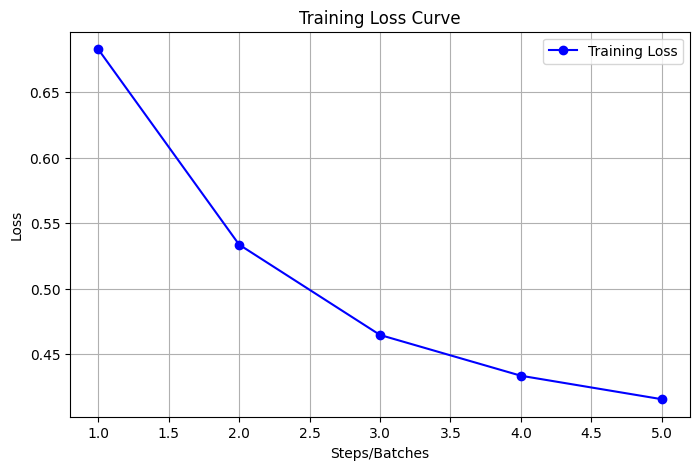

In [ ]:
import matplotlib.pyplot as plt

def plot_train_loss(train_losses, avg=True):
    """
    Plots training loss curve.

    Args:
        train_losses (list): List of per-epoch training losses.
        avg (bool): If True, smooths the curve if you logged batch-level losses instead of epoch losses.
    """
    plt.figure(figsize=(8,5))

    if avg and len(train_losses) > 20:
        # Smooth curve by averaging into ~20 points
        N = max(1, len(train_losses)//20)
        smoothed = [sum(train_losses[i:i+N])/N for i in range(0, len(train_losses), N)]
        plt.plot(range(1, len(smoothed)+1), smoothed, 'bo-', label='Training Loss (avg)')
    else:
        plt.plot(range(1, len(train_losses)+1), train_losses, 'bo-', label='Training Loss')

    plt.title('Training Loss Curve')
    plt.xlabel('Epochs' if avg else 'Steps/Batches')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
train_losses = [0.6826, 0.5336, 0.4647, 0.4336, 0.4157]  # per epoch
plot_train_loss(train_losses, avg=False)

PRECISION-RECALL CURVE

Ensuring the latest version of torchmetrics is installed...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 49.5 MB/s eta 0:00:00

--- Generating Precision-Recall Curve ---


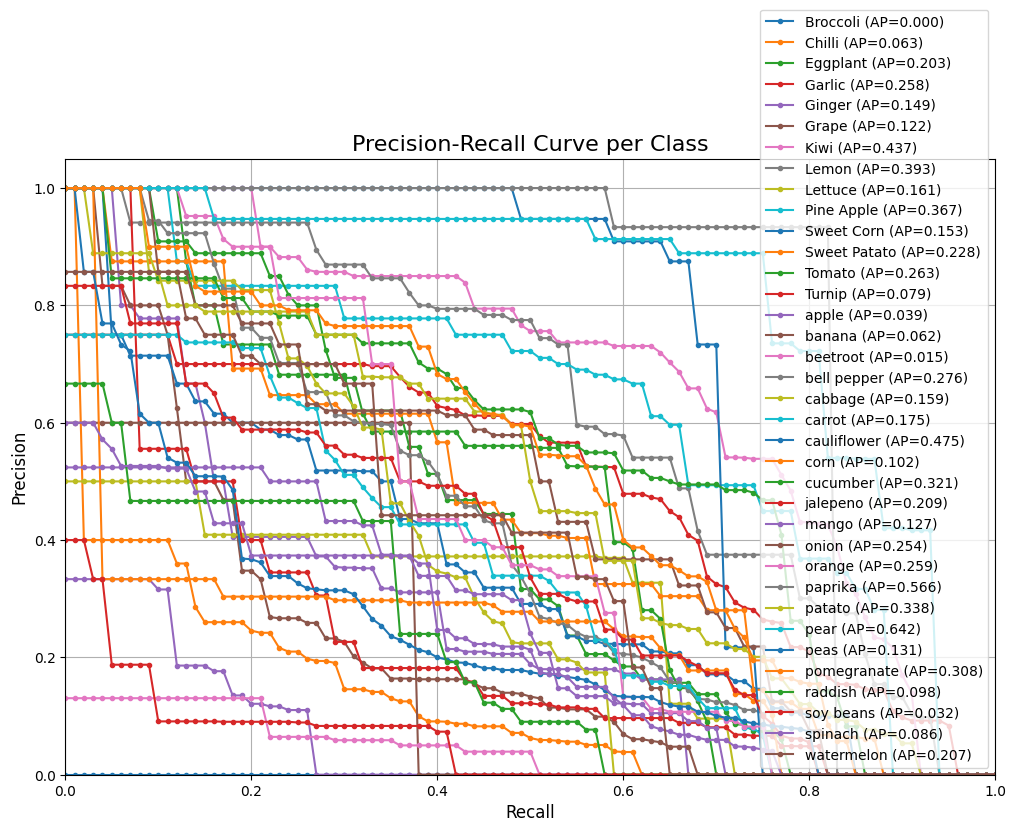

In [ ]:

print("Ensuring the latest version of torchmetrics is installed...")
!pip install -U --quiet torchmetrics

# 2. Import necessary libraries
import torch
import torchmetrics
import matplotlib.pyplot as plt

def plot_precision_recall_curve(predictions, ground_truths, class_names):
    """
    Calculates and plots the standard Precision-Recall curve for each class.
    This version is tailored to the specific output format of the installed torchmetrics library.
    """
    # Convert data to the format torchmetrics expects
    preds_tensor = [{'boxes': torch.tensor(p['boxes']), 'scores': torch.tensor(p['scores']), 'labels': torch.tensor(p['labels'])} for p in predictions]
    target_tensor = [{'boxes': torch.tensor(gt['boxes']), 'labels': torch.tensor(gt['labels'])} for gt in ground_truths]

    # Initialize the metric, asking for the full summary data
    metric = torchmetrics.detection.MeanAveragePrecision(
        box_format='xyxy',
        class_metrics=True,
        extended_summary=True
    )

    metric.update(preds_tensor, target_tensor)
    results = metric.compute()

    # Create the plot
    plt.figure(figsize=(12, 8))

    # The standard recall steps are 101 points from 0.0 to 1.0
    recall_steps = torch.linspace(0, 1, 101)

    for i, class_id_tensor in enumerate(results['classes']):
        class_id = class_id_tensor.item()
        class_name = class_names[class_id]
        precision_values = results['precision'][0, :, i, 0, 2]

        avg_precision = results['map_per_class'][i]

        # Plot the curve
        plt.plot(recall_steps, precision_values, marker='.', label=f'{class_name} (AP={avg_precision:.3f})')

    # Add titles and labels
    plt.title('Precision-Recall Curve per Class', fontsize=16)
    plt.xlabel('Recall', fontsize=12)
    plt.ylabel('Precision', fontsize=12)
    plt.legend()
    plt.grid(True)
    plt.xlim([0, 1])
    plt.ylim([0, 1.05])
    plt.show()

# --- HOW TO USE ---
# This cell will now work. Run it after collecting your data.

print("\n--- Generating Precision-Recall Curve ---")
plot_precision_recall_curve(all_predictions, all_ground_truths, CLASS_NAMES)

CONFUSION MATRIX


--- Generating Confusion Matrix ---


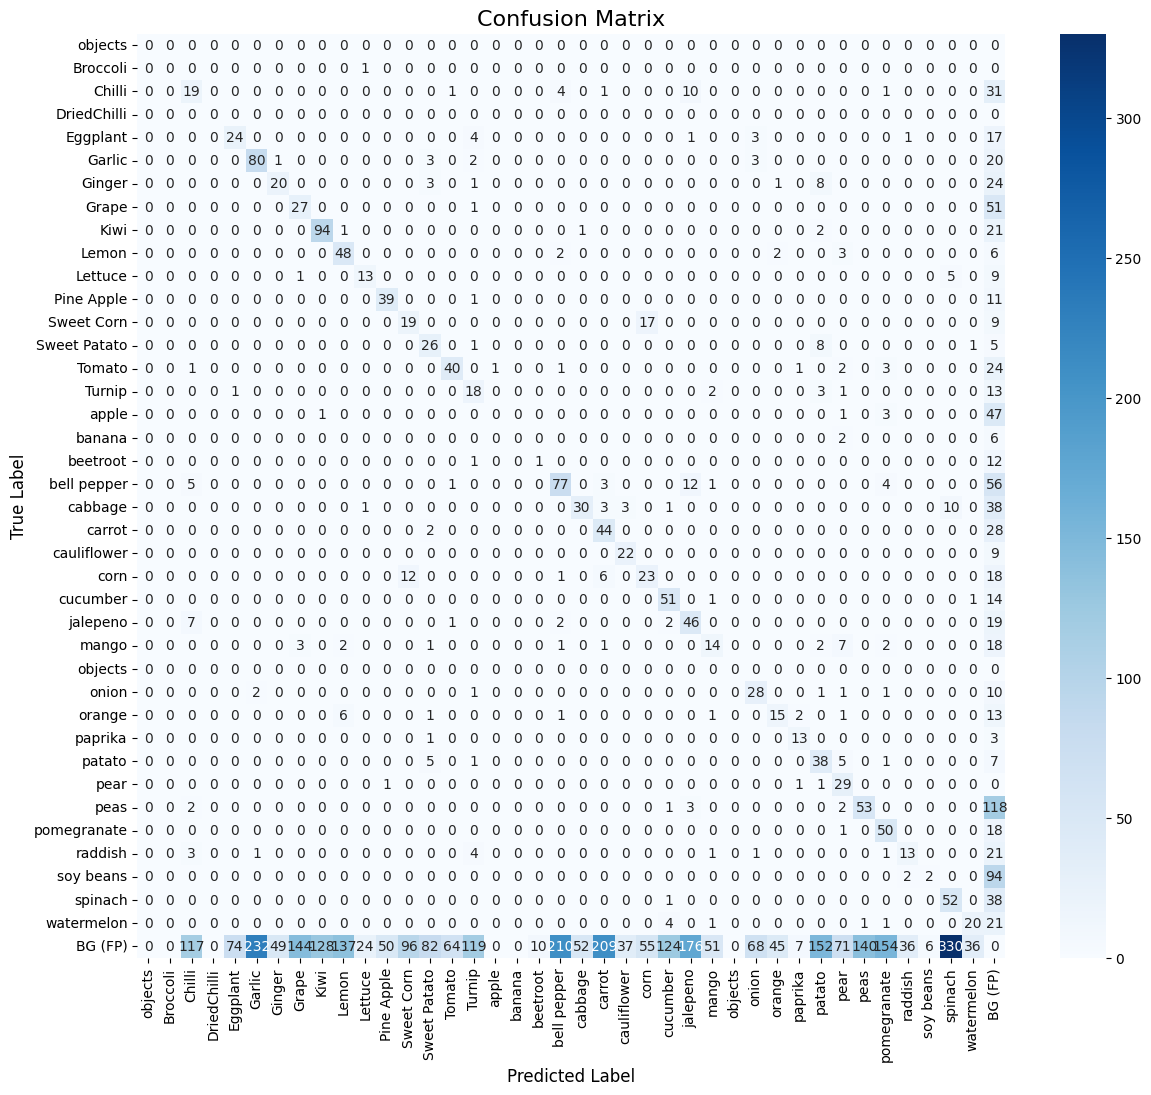

In [ ]:
# Cell 3: Confusion Matrix

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def calculate_iou(box1, box2):
    # Calculates Intersection over Union, a measure of how much two boxes overlap
    x1, y1, x2, y2 = box1
    x1_p, y1_p, x2_p, y2_p = box2
    inter_x1 = max(x1, x1_p); inter_y1 = max(y1, y1_p)
    inter_x2 = min(x2, x2_p); inter_y2 = min(y2, y2_p)
    inter_area = max(0, inter_x2 - inter_x1) * max(0, inter_y2 - inter_y1)
    box1_area = (x2 - x1) * (y2 - y1); box2_area = (x2_p - x1_p) * (y2_p - y1_p)
    iou = inter_area / float(box1_area + box2_area - inter_area)
    return iou

def plot_confusion_matrix(predictions, ground_truths, class_names, iou_threshold=0.5, score_threshold=0.3):
    """
    Generates and plots a confusion matrix for object detection.

    Args:
        predictions (list of dict): Standardized prediction data.
        ground_truths (list of dict): Standardized ground truth data.
        class_names (list of str): List of class names, MUST NOT include background.
        iou_threshold (float): IoU to consider a detection a 'match'.
        score_threshold (float): Confidence score to consider a prediction valid.
    """
    num_classes = len(class_names)

    matrix = np.zeros((num_classes + 1, num_classes + 1), dtype=np.int32)

    for img_preds, img_gts in zip(predictions, ground_truths):
        gt_boxes = list(img_gts['boxes']); gt_labels = list(img_gts['labels'])
        pred_boxes = list(img_preds['boxes']); pred_labels = list(img_preds['labels']); pred_scores = list(img_preds['scores'])

        valid_preds_indices = [i for i, score in enumerate(pred_scores) if score >= score_threshold]

        matches = []
        for gt_idx, (gt_box, gt_label) in enumerate(zip(gt_boxes, gt_labels)):
            best_iou = 0
            best_pred_idx = -1
            for pred_idx in valid_preds_indices:
                if pred_idx in [m[1] for m in matches]: continue
                iou = calculate_iou(gt_box, pred_boxes[pred_idx])
                if iou > best_iou:
                    best_iou = iou
                    best_pred_idx = pred_idx

            if best_iou >= iou_threshold:
                matches.append((gt_idx, best_pred_idx))

        # Populate the matrix based on matches
        for gt_idx, pred_idx in matches:
            true_label = gt_labels[gt_idx]
            pred_label = pred_labels[pred_idx]
            # row = true_label - 1, col = pred_label - 1
            matrix[true_label - 1, pred_label - 1] += 1

        # Unmatched predictions are False Positives
        unmatched_preds = set(valid_preds_indices) - set([m[1] for m in matches])
        for pred_idx in unmatched_preds:
            pred_label = pred_labels[pred_idx]
            # row = background, col = pred_label - 1
            matrix[num_classes, pred_label - 1] += 1

        # Unmatched ground truths are False Negatives
        unmatched_gts = set(range(len(gt_boxes))) - set([m[0] for m in matches])
        for gt_idx in unmatched_gts:
            true_label = gt_labels[gt_idx]
            # row = true_label - 1, col = background
            matrix[true_label - 1, num_classes] += 1

    # Plotting the matrix
    fig, ax = plt.subplots(figsize=(14, 12))
    plot_labels = class_names + ['BG (FP)'] # BG = Background (False Positives)

    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=plot_labels, yticklabels=plot_labels, ax=ax)

    ax.set_title('Confusion Matrix', fontsize=16)
    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)
    plt.show()

CLASS_NAMES_NO_BG = CLASS_NAMES[1:]

print("\n--- Generating Confusion Matrix ---")
plot_confusion_matrix(all_predictions, all_ground_truths, CLASS_NAMES_NO_BG)

Running on: cuda
loading annotations into memory...
Done (t=0.17s)
creating index...
index created!
Category mapping: {0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8, 8: 9, 9: 10, 10: 11, 11: 12, 12: 13, 13: 14, 14: 15, 15: 16, 16: 17, 17: 18, 18: 19, 19: 20, 20: 21, 21: 22, 22: 23, 23: 24, 24: 25, 25: 26, 26: 27, 27: 28, 28: 29, 29: 30, 30: 31, 31: 32, 32: 33, 33: 34, 34: 35, 35: 36, 36: 37, 37: 38, 38: 39}
Total classes (with background): 40
Validation samples: 770


Faster R-CNN Eval:   0%|          | 2/770 [00:00<01:39,  7.70it/s]

GT: 10, Pred: 10
GT: 20, Pred: 20


Faster R-CNN Eval:   1%|          | 4/770 [00:00<01:20,  9.50it/s]

GT: 8, Pred: 8
GT: 32, Pred: 32
GT: 21, Pred: 21


Faster R-CNN Eval:   1%|          | 8/770 [00:00<01:14, 10.21it/s]

GT: 22, Pred: 22
GT: 3, Pred: 26
GT: 35, Pred: 35


Faster R-CNN Eval:   1%|▏         | 10/770 [00:01<01:13, 10.30it/s]

GT: 23, Pred: 23


Faster R-CNN Eval: 100%|██████████| 770/770 [01:12<00:00, 10.67it/s]



Classification Report:

              precision    recall  f1-score   support

           2       0.00      0.00      0.00         1
           3       0.57      0.62      0.59        26
           5       0.95      0.75      0.84        24
           6       0.97      1.00      0.99        33
           7       1.00      0.62      0.76        21
           8       0.74      0.83      0.78        24
           9       0.96      0.96      0.96        27
          10       0.78      0.86      0.82        21
          11       0.83      0.43      0.57        23
          12       0.96      0.96      0.96        23
          13       0.57      0.57      0.57        21
          14       0.52      0.79      0.63        14
          15       0.82      0.87      0.84        31
          16       0.57      0.75      0.65        28
          17       0.00      0.00      0.00         3
          18       0.00      0.00      0.00         3
          19       1.00      0.50      0.67         2
  

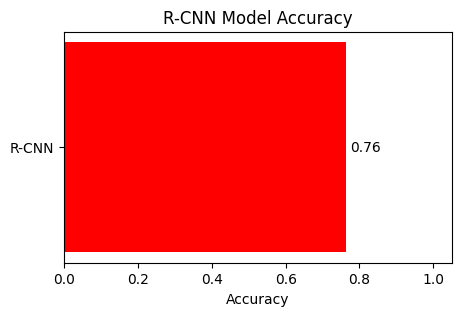

In [ ]:
# ================================================================
# Faster R-CNN Evaluation (with COCO JSON Annotations, remapped IDs)
# ================================================================
import torch
from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from pycocotools.coco import COCO
import torchvision.transforms as T
from PIL import Image
import os
from sklearn.metrics import classification_report, accuracy_score
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device)

# -------------------------
# 1. Dataset Loader (COCO style, safe for missing images + ID remap)
# -------------------------
class CocoDataset(torch.utils.data.Dataset):
    def __init__(self, root, annFile, transform=None):
        self.root = root
        self.coco = COCO(annFile)
        self.ids = list(self.coco.imgs.keys())
        self.transform = transform

        # Build category remapping: original ID → contiguous label
        cats = self.coco.loadCats(self.coco.getCatIds())
        self.cat_id_to_label = {cat["id"]: i+1 for i, cat in enumerate(cats)}  # +1 for background
        self.num_classes = len(cats) + 1  # +1 for background

        print("Category mapping:", self.cat_id_to_label)
        print("Total classes (with background):", self.num_classes)

    def __getitem__(self, index):
        img_id = self.ids[index]
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)
        path = self.coco.loadImgs(img_id)[0]['file_name']

        img_path = os.path.join(self.root, path)
        if not os.path.exists(img_path):
            print(f"[WARNING] Missing image: {img_path}, skipping...")
            return None  # flag as missing

        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)

        # Remap category IDs
        labels = [self.cat_id_to_label[ann['category_id']] for ann in anns if ann['category_id'] in self.cat_id_to_label]

        return img, labels

    def __len__(self):
        return len(self.ids)


# -------------------------
# 1b. Custom collate function
# -------------------------
def coco_collate_fn(batch):
    # Drop None samples
    batch = [b for b in batch if b is not None]
    if len(batch) == 0:
        return None
    imgs, labels = zip(*batch)
    return torch.stack(imgs, 0), labels


transform = T.Compose([T.ToTensor()])
img_dir = "/content/Vegetables-12/valid"        # <-- EDIT
ann_file = "/content/Vegetables-12/valid/_annotations.coco.json"  # <-- EDIT

dataset = CocoDataset(img_dir, ann_file, transform=transform)
dataloader = DataLoader(dataset, batch_size=1, shuffle=False, collate_fn=coco_collate_fn)
print("Validation samples:", len(dataset))

# -------------------------
# 2. Build Faster R-CNN
# -------------------------
NUM_CLASSES = dataset.num_classes  # auto from JSON
model = fasterrcnn_resnet50_fpn(weights=None, num_classes=NUM_CLASSES)

# Load checkpoint (trained with matching num_classes)
checkpoint = torch.load('/content/drive/MyDrive/Cabage_Dog/R-CNN/JustinYongWeiLiRCNN_detector.pth', map_location=device)
model.load_state_dict(checkpoint, strict=False)
model.eval().to(device)

# -------------------------
# 3. Evaluation
# -------------------------
y_true, y_pred = [], []

with torch.no_grad():
    for batch in tqdm(dataloader, desc="Faster R-CNN Eval"):
        if batch is None:  # all images in this batch missing
            continue
        imgs, labels = batch
        imgs = imgs.to(device)

        # Forward pass
        outputs = model([imgs[0]])

        if len(outputs[0]['labels']) > 0 and len(labels[0]) > 0:
            pred_cls = int(outputs[0]['labels'][0].cpu().numpy())
            gt_cls = labels[0][0]

            y_true.append(gt_cls)
            y_pred.append(pred_cls)

            # Debug first few
            if len(y_true) < 10:
                print(f"GT: {gt_cls}, Pred: {pred_cls}")

# -------------------------
# 4. Report
# -------------------------
if len(y_true) == 0 or len(y_pred) == 0:
    print("\n[WARNING] No predictions or ground-truth labels collected!")
    print("→ Check if model is producing detections OR dataset paths are correct.")
else:
    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, zero_division=0))
    print("Accuracy:", accuracy_score(y_true, y_pred))


# -------------------------
# 5. Accuracy Plot
# -------------------------
import matplotlib.pyplot as plt

if len(y_true) > 0:
    acc = accuracy_score(y_true, y_pred)
    plt.figure(figsize=(5, 3))
    plt.barh(["R-CNN"], [acc], color="red")
    plt.xlabel("Accuracy")
    plt.title("R-CNN Model Accuracy")
    plt.xlim(0, 1.05)
    plt.text(acc + 0.01, 0, f"{acc:.2f}", va="center")
    plt.show()


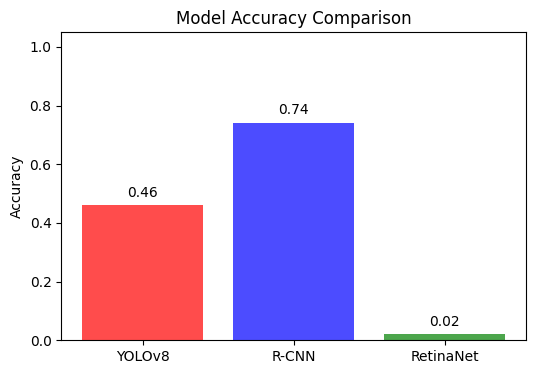

In [ ]:
# ================================================================
# Model Accuracy Comparison (YOLOv8 vs Faster R-CNN vs RetinaNet)
# ================================================================
import matplotlib.pyplot as plt

# -------------------------
# 1. Fill in accuracies from reports
# -------------------------
accuracies = {
    "YOLOv8": 0.46,    # <-- replace with your YOLO result
    "R-CNN": 0.74,     # <-- replace with Faster R-CNN result
    "RetinaNet": 0.02  # <-- replace with your teammate's RetinaNet result
}

# -------------------------
# 2. Plot bar chart
# -------------------------a
plt.figure(figsize=(6, 4))
bars = plt.bar(accuracies.keys(), accuracies.values(), color=["red", "blue", "green"], alpha=0.7)

# Annotate bars with accuracy values
for bar, acc in zip(bars, accuracies.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
             f"{acc:.2f}", ha="center", va="bottom", fontsize=10)

plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.show()


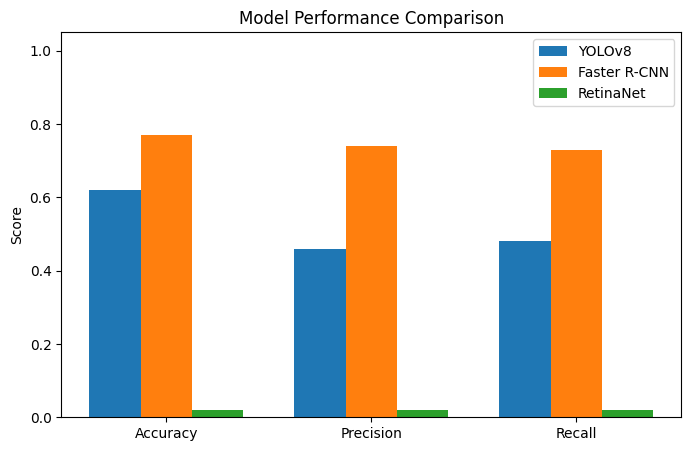

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Example (replace with real values from YOLO, RCNN, RetinaNet)
metrics = ["Accuracy", "Precision", "Recall"]
yolo_vals    = [0.62, 0.46, 0.48]
rcnn_vals    = [0.77, 0.74, 0.73]
retina_vals  = [0.02, 0.02, 0.02]

x = np.arange(len(metrics))  # positions
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
ax.bar(x - width, yolo_vals, width, label="YOLOv8")
ax.bar(x, rcnn_vals, width, label="Faster R-CNN")
ax.bar(x + width, retina_vals, width, label="RetinaNet")

ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()